## Data Preprocessing with Scanpy

In [1]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from lung droplet folder(s) into an AnnData object

In [3]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Lung-10X_P7_8"),
# sc.read_10x_mtx("droplet/Lung-10X_P7_9"),
# sc.read_10x_mtx("droplet/Lung-10X_P8_12"),
# sc.read_10x_mtx("droplet/Lung-10X_P8_13"),

# checking how visualizations look when lung_droplet_annotation.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Lung-10X_P7_8"),
    sc.read_10x_mtx("../droplet/Lung-10X_P7_9"),
    sc.read_10x_mtx("../droplet/Lung-10X_P8_12"),
    sc.read_10x_mtx("../droplet/Lung-10X_P8_13"),
])

tiss.obs_names_make_unique()

tiss.obs


    reading ../droplet/Lung-10X_P7_8/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Lung-10X_P7_9/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Lung-10X_P8_12/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Lung-10X_P8_13/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAACGGGAGGATATAC-1
AAACGGGTCTCGTATT-1
AAAGATGCAGATCTGT-1
AAATGCCAGATAGTCA-1
AAATGCCCAAACTGCT-1
...
TTTGTCATCTTTACAC-1-1
TTTGTCATCTTTACGT-1-1
TTTGTCATCTTTAGGG-1-1
TTTGTCATCTTTAGTC-1-1


In [4]:
tiss.obs

""
AAACGGGAGGATATAC-1
AAACGGGTCTCGTATT-1
AAAGATGCAGATCTGT-1
AAATGCCAGATAGTCA-1
AAATGCCCAAACTGCT-1
...
TTTGTCATCTTTACAC-1-1
TTTGTCATCTTTACGT-1-1
TTTGTCATCTTTAGGG-1-1
TTTGTCATCTTTAGTC-1-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [5]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 1471202 cells that have less than 500 genes expressed
filtered out 59 cells that have less than 1000 counts


,n_genes,n_counts
AAACGGGAGGATATAC-1,2877,15861.0
AAACGGGTCTCGTATT-1,2262,6509.0
AAAGATGCAGATCTGT-1,3047,12186.0
AAATGCCAGATAGTCA-1,1650,4401.0
AAATGCCCAAACTGCT-1,3239,9211.0
...,...,...
TTTGGTTTCTCTAAGG-1-1,1059,2238.0
TTTGTCAAGAGTCGGT-1-1,1551,3041.0
TTTGTCACATATGAGA-1-1,2623,7843.0
TTTGTCAGTGGCGAAT-1-1,2267,6014.0


## Normalization

In [6]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [7]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


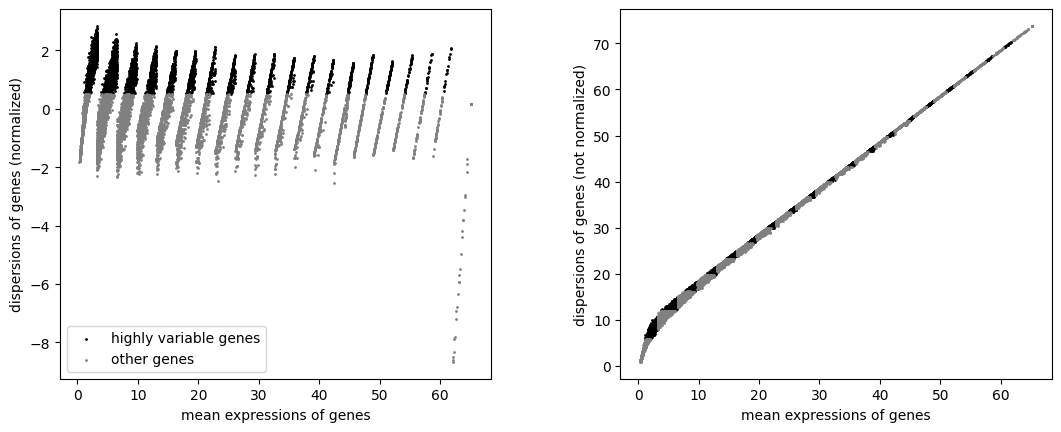

In [8]:
sc.pl.highly_variable_genes(tiss)

In [9]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Xkr4,0.000310,0.016185,True,45.534225,54.099500,1.416906
Sox17,0.075737,0.362560,True,2.625497,7.882995,1.470219
2610203C22Rik,0.009294,0.106181,True,12.371978,20.246911,0.960552
3110035E14Rik,0.000483,0.026092,True,55.274568,63.877755,1.705225
Mybl1,0.000976,0.031185,True,38.919182,47.522369,1.611625
...,...,...,...,...,...,...
Arhgap6,0.088110,0.335633,True,1.771010,6.301853,0.729791
Mid1,0.011790,0.121648,True,8.717214,16.492422,0.792321
G530011O06Rik,0.025629,0.190561,True,5.775313,13.130736,1.351562
Tmlhe,0.006799,0.095468,True,12.917751,21.086688,1.723310


## Dimensionality Reduction
Through PCA

In [10]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:01)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


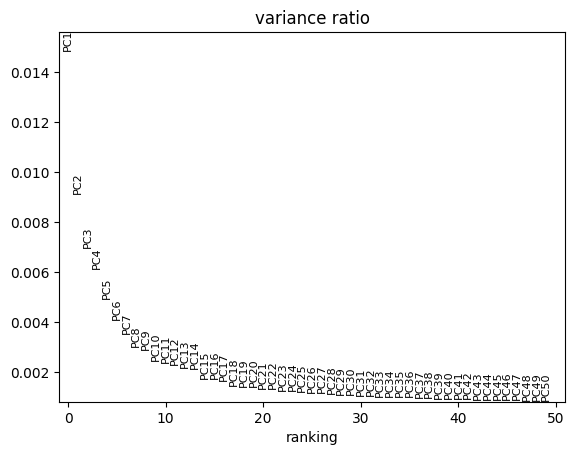

In [11]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [12]:
lung_annotations = pd.read_csv("../annotations/Lung_droplet_annotation.csv")

y = lung_annotations["cell_ontology_class"].values
y


array(['myeloid cell', 'alveolar macrophage', 'B cell', ...,
       'stromal cell', nan, 'stromal cell'], shape=(5449,), dtype=object)

In [13]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAACGGGAGGATATAC-1,2877,15861.0,myeloid cell
AAACGGGTCTCGTATT-1,2262,6509.0,alveolar macrophage
AAAGATGCAGATCTGT-1,3047,12186.0,B cell
AAATGCCAGATAGTCA-1,1650,4401.0,natural killer cell
AAATGCCCAAACTGCT-1,3239,9211.0,T cell
...,...,...,...
TTTGGTTTCTCTAAGG-1-1,1059,2238.0,stromal cell
TTTGTCAAGAGTCGGT-1-1,1551,3041.0,stromal cell
TTTGTCACATATGAGA-1-1,2623,7843.0,stromal cell
TTTGTCAGTGGCGAAT-1-1,2267,6014.0,NaN


## Clustering


In [14]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed connectivities (0:00:01)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 13 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


In [15]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAACGGGAGGATATAC-1,2877,15861.0,myeloid cell,2
AAACGGGTCTCGTATT-1,2262,6509.0,alveolar macrophage,6
AAAGATGCAGATCTGT-1,3047,12186.0,B cell,7
AAATGCCAGATAGTCA-1,1650,4401.0,natural killer cell,1
AAATGCCCAAACTGCT-1,3239,9211.0,T cell,12
...,...,...,...,...
TTTGGTTTCTCTAAGG-1-1,1059,2238.0,stromal cell,0
TTTGTCAAGAGTCGGT-1-1,1551,3041.0,stromal cell,3
TTTGTCACATATGAGA-1-1,2623,7843.0,stromal cell,4
TTTGTCAGTGGCGAAT-1-1,2267,6014.0,NaN,10


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5449 samples in 0.001s...
[t-SNE] Computed neighbors for 5449 samples in 0.113s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5449
[t-SNE] Computed conditional probabilities for sample 2000 / 5449
[t-SNE] Computed conditional probabilities for sample 3000 / 5449
[t-SNE] Computed conditional probabilities for sample 4000 / 5449
[t-SNE] Computed conditional probabilities for sample 5000 / 5449
[t-SNE] Computed conditional probabilities for sample 5449 / 5449
[t-SNE] Mean sigma: 1.084093
[t-SNE] KL divergence after 250 iterations with early exaggeration: 68.694687
[t-SNE] KL divergence after 1000 iterations: 1.153624
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:07)


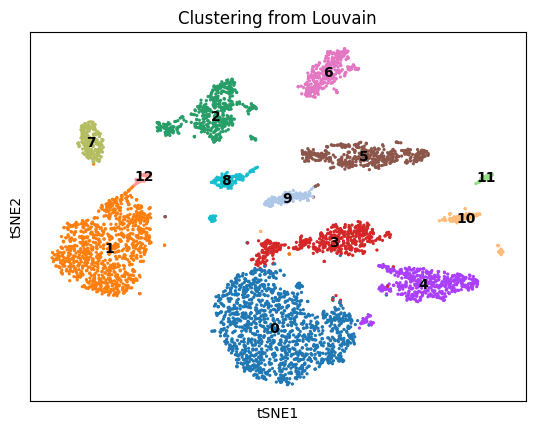

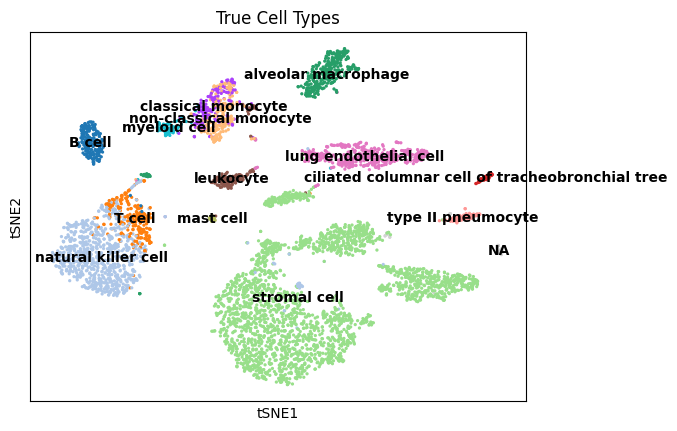

In [16]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((4359, 5314), (1090, 5314), (4359,), (1090,))

## scikit-learn Machine Learning Classifiers

In [18]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [20]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9844

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        38
           1       0.97      0.97      0.97        58
           2       1.00      1.00      1.00        68
           3       1.00      1.00      1.00        10
           4       0.97      0.89      0.93        36
           5       1.00      0.97      0.98        31
           6       0.99      0.98      0.98        87
           7       1.00      0.67      0.80         3
           8       0.85      1.00      0.92        17
           9       0.98      0.99      0.98       163
          10       0.96      0.98      0.97        49
          11       0.99      1.00      0.99       498
          12       1.00      1.00      1.00        27
          13       1.00      0.80      0.89         5

    accuracy                           0.98      1090
   macro avg       0.98      0.94      0.96      1090
weighted

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Random Forest
✅ Accuracy: 0.9725

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        38
           1       0.98      0.93      0.96        58
           2       1.00      1.00      1.00        68
           3       1.00      1.00      1.00        10
           4       0.89      0.92      0.90        36
           5       1.00      0.97      0.98        31
           6       0.98      0.99      0.98        87
           7       1.00      0.67      0.80         3
           8       1.00      0.47      0.64        17
           9       0.93      0.99      0.96       163
          10       0.96      0.96      0.96        49
          11       0.99      0.99      0.99       498
          12       1.00      1.00      1.00        27
          13       1.00      0.20      0.33         5

    accuracy                           0.97      1090
   macro avg       0.98      0.86      0.89      1090
weighted avg  

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Naive Bayes
✅ Accuracy: 0.6963

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.26      0.41        38
           1       0.53      0.28      0.36        58
           2       0.54      0.66      0.59        68
           3       0.56      1.00      0.71        10
           4       0.33      0.31      0.32        36
           5       0.88      0.23      0.36        31
           6       0.49      0.60      0.54        87
           7       0.00      0.00      0.00         3
           8       0.36      0.53      0.43        17
           9       0.81      0.67      0.73       163
          10       0.43      0.24      0.31        49
          11       0.78      0.91      0.84       498
          12       0.85      0.81      0.83        27
          13       0.29      0.40      0.33         5

    accuracy                           0.70      1090
   macro avg       0.55      0.49      0.48      1090
weighted avg    

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Pytorch Neural Network

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [22]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [23]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 2.2789
Epoch 2, Loss: 1.1966
Epoch 3, Loss: 0.5091
Epoch 4, Loss: 0.2919
Epoch 5, Loss: 0.1535
Epoch 6, Loss: 0.0902
Epoch 7, Loss: 0.0644
Epoch 8, Loss: 0.0493
Epoch 9, Loss: 0.0365
Epoch 10, Loss: 0.0281


In [25]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9761

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        38
           1       0.93      0.95      0.94        58
           2       0.97      1.00      0.99        68
           3       1.00      1.00      1.00        10
           4       0.97      0.92      0.94        36
           5       1.00      0.90      0.95        31
           6       0.99      0.97      0.98        87
           7       1.00      0.33      0.50         3
           8       0.89      1.00      0.94        17
           9       0.98      0.98      0.98       163
          10       0.91      1.00      0.95        49
          11       0.99      0.99      0.99       498
          12       0.86      0.93      0.89        27
          13       1.00      0.60      0.75         5

    accuracy                           0.98      1090
   macro avg       0.96      0.90      0.91      1090
weighted avg 

## Visualizing Model Results using TSNE

In [26]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [27]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [28]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering


/var/folders/wk/gl6vb2s945jbqmt08f1p2pdw0000gn/T/ipykernel_48736/845363431.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tiss, resolution=3.5)


    finished: found 40 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:01)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5449 samples in 0.001s...
[t-SNE] Computed neighbors for 5449 samples in 0.111s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5449
[t-SNE] Computed conditional probabilities for sample 2000 / 5449
[t-SNE] Computed conditional probabilities for sample 3000 / 5449
[t-SNE] Computed conditional probabilities for sample 4000 / 5449
[t-SNE] Computed conditional probabilities for sample 5000 / 5449
[t-SNE] Computed conditional probabilities for sample 5449 / 5449
[t-SNE] Mean sigma: 1.084093
[t-SNE] KL divergence after 250 iterations with early exaggeration: 68.694687
[t-SNE] KL divergence after 1000 iterations: 1.153624
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:0

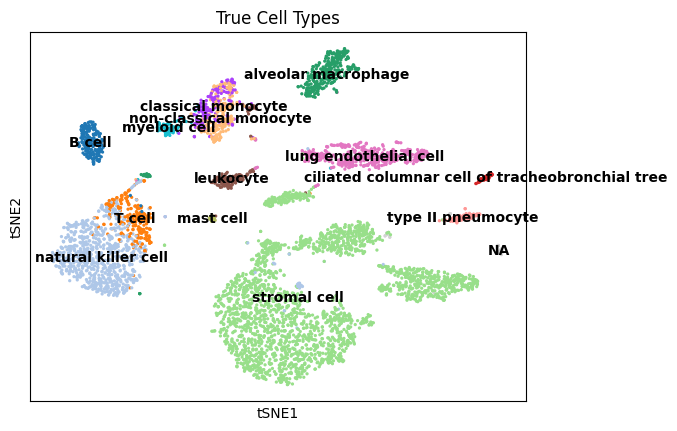

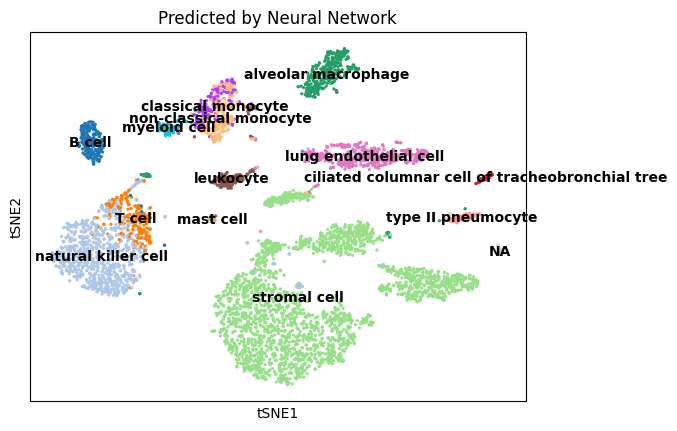

In [29]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


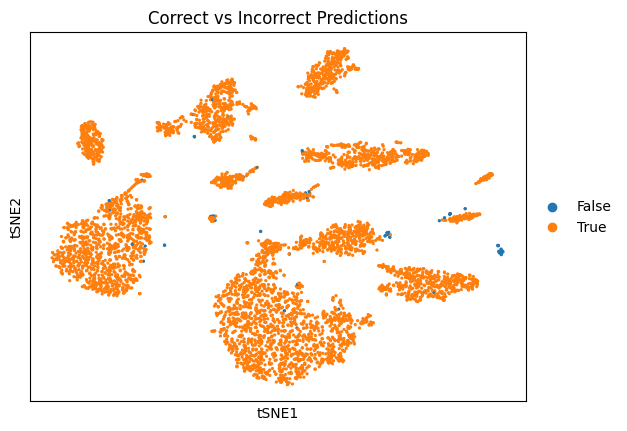

In [30]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")
